## Event Impact by Station Cluster

#### How much do time, holiday, weather and direction features influence cycling at each station type?

This notebook combines the station-cluster file with cached Random Forest SHAP values. The SHAP cache is already computed on a balanced test sample (`1,500` observations per cluster), so the heatmap compares clusters without one large cluster dominating the average.

**1. Imports and paths**

In [1]:
import pickle
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "Cluster" / "station_profiles_clustered.csv").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_DIR = PROJECT_ROOT / "data"
CLUSTER_FILE = PROJECT_ROOT / "Cluster" / "station_profiles_clustered.csv"
SHAP_FILE = DATA_DIR / "shap_values_stratified.pkl"

if not SHAP_FILE.exists():
    SHAP_FILE = DATA_DIR / "shap_values.pkl"

print(f"Project root: {PROJECT_ROOT}")
print(f"Cluster file: {CLUSTER_FILE.relative_to(PROJECT_ROOT)}")
print(f"SHAP file: {SHAP_FILE.relative_to(PROJECT_ROOT)}")

Project root: .
Cluster file: Cluster/station_profiles_clustered.csv
SHAP file: data/shap_values_stratified.pkl


**2. Load station clusters and cached SHAP values**

In [2]:
station_df = pd.read_csv(CLUSTER_FILE)
station_df = station_df[["site_id", "cluster", "naam", "lat", "long"]].copy()
station_df["cluster"] = station_df["cluster"].astype(int)

with open(SHAP_FILE, "rb") as f:
    shap_raw = pickle.load(f)

sample_df = shap_raw["sample"].copy()
feature_columns = list(shap_raw["feature_columns"])
shap_values = np.asarray(shap_raw["shap_values"])

print(f"Station profiles: {station_df.shape}")
print(f"SHAP sample: {sample_df.shape}")
print(f"Features in SHAP cache: {len(feature_columns)}")
station_df.head()

Station profiles: (140, 5)
SHAP sample: (4500, 37)
Features in SHAP cache: 20


,site_id,cluster,naam,lat,long
0,1,0,Machelen,50.916183,4.456122
1,2,0,Brasschaat 2,51.275120,4.471690
2,3,0,Brasschaat 1,51.275030,4.472220
3,4,0,Balen 1,51.160230,5.190110
4,5,0,Balen 2,51.160180,5.190030


**3. Build long-format SHAP table**

In [3]:
EVENT_FEATURES = [
    "hour",
    "day_of_week",
    "month",
    "is_holiday",
    "days_to_nearest_holiday",
    "is_in",
    "temp_c",
    "humidity",
    "dewpoint_c",
    "precip_mm",
    "rain_mm",
    "snowfall_cm",
    "windspeed_kmh",
    "winddir_deg",
    "windgust_kmh",
    "wind_impact",
]
EVENT_FEATURES = [f for f in EVENT_FEATURES if f in feature_columns]

shap_df = pd.DataFrame(shap_values, columns=feature_columns)
shap_df["site_id"] = sample_df["site_id"].to_numpy()

if "cluster" in sample_df.columns:
    shap_df["cluster"] = sample_df["cluster"].astype(int).to_numpy()
else:
    shap_df = shap_df.merge(station_df[["site_id", "cluster"]], on="site_id", how="left")

shap_long = shap_df.melt(
    id_vars=["site_id", "cluster"],
    value_vars=EVENT_FEATURES,
    var_name="event_feature",
    value_name="shap_value",
)

print(f"Rows in long SHAP table: {len(shap_long):,}")
print("Sample size by cluster:")
print(shap_df["cluster"].value_counts().sort_index())
shap_long.head()

Rows in long SHAP table: 72,000
Sample size by cluster:
cluster
0    1500
1    1500
2    1500
Name: count, dtype: int64


,site_id,cluster,event_feature,shap_value
0,119,0,hour,12.866286
1,22,0,hour,-1.441721
2,131,0,hour,-7.057374
3,124,0,hour,7.060172
4,82,0,hour,3.527191


**4. Compute the cluster x feature impact matrix**

In [4]:
impact_matrix = (
    shap_long
    .groupby(["cluster", "event_feature"], observed=True)["shap_value"]
    .mean()
    .unstack()
)

feature_order = impact_matrix.abs().mean(axis=0).sort_values(ascending=False).index
impact_matrix = impact_matrix[feature_order]
impact_matrix.round(2)

event_feature,hour,is_holiday,humidity,windspeed_kmh,days_to_nearest_holiday,windgust_kmh,day_of_week,dewpoint_c,temp_c,precip_mm,winddir_deg,is_in,wind_impact,rain_mm,month,snowfall_cm
cluster,,,,,,,,,,,,,,,,
0,0.17,-0.21,0.14,0.13,0.07,0.08,0.04,0.11,-0.16,0.06,0.05,-0.10,0.03,0.03,0.00,0.0
1,0.93,-1.35,0.66,0.45,0.34,0.29,0.33,0.11,-0.04,0.22,0.20,0.02,0.11,0.11,0.09,0.0
2,1.38,0.03,0.27,0.17,0.21,0.09,0.06,0.16,-0.17,0.07,0.03,0.12,0.04,0.03,-0.01,-0.0


**5. Visualize event impact**

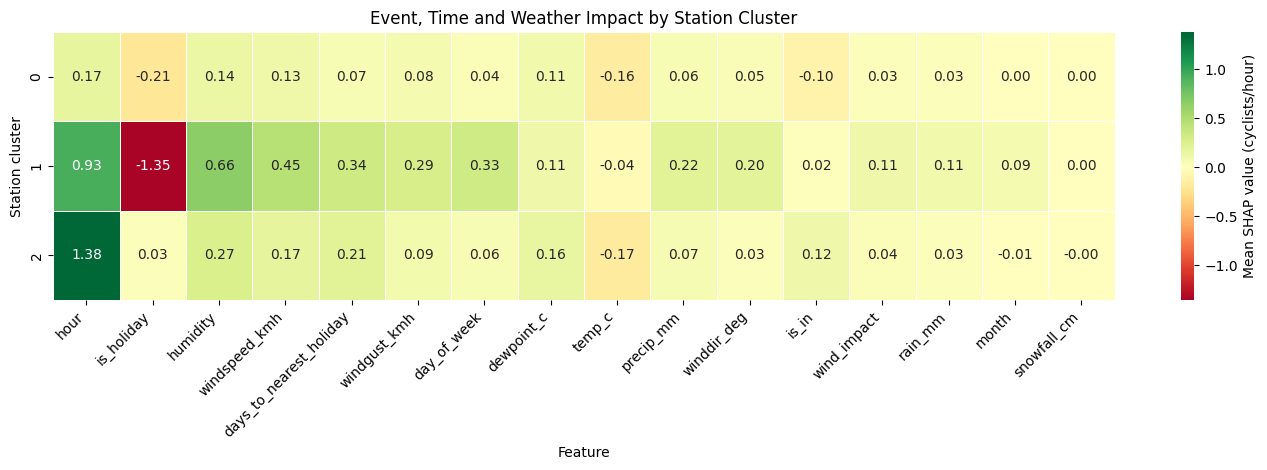

In [5]:
from matplotlib.colors import LinearSegmentedColormap

fig, ax = plt.subplots(figsize=(14, 4.8))
shap_cmap = LinearSegmentedColormap.from_list(
    "muted_shap_diverging",
    ["#C95D63", "#F6F3EF", "#2F6F9F"],
)

sns.heatmap(
    impact_matrix,
    annot=True,
    fmt=".2f",
    cmap=shap_cmap,
    center=0,
    linewidths=0.5,
    linecolor="#E0E0E0",
    cbar_kws={"label": "Mean SHAP value (cyclists/hour)"},
    ax=ax,
)

ax.set_title("Event, Time and Weather Impact by Station Cluster")
ax.set_xlabel("Feature")
ax.set_ylabel("Station cluster")
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right")
sns.despine(ax=ax, left=True, bottom=True)
plt.tight_layout()
plt.show()

**6. Top positive and negative effects**

In [6]:
top_effects = []
for cluster_id, row in impact_matrix.iterrows():
    positives = row[row > 0].sort_values(ascending=False).head(3)
    negatives = row[row < 0].sort_values().head(3)

    for feature, value in positives.items():
        top_effects.append({
            "cluster": int(cluster_id),
            "direction": "positive",
            "feature": feature,
            "mean_shap": value,
        })
    for feature, value in negatives.items():
        top_effects.append({
            "cluster": int(cluster_id),
            "direction": "negative",
            "feature": feature,
            "mean_shap": value,
        })

top_effects_df = pd.DataFrame(top_effects)
top_effects_df["mean_shap"] = top_effects_df["mean_shap"].round(2)
top_effects_df

,cluster,direction,feature,mean_shap
0,0,positive,hour,0.17
1,0,positive,humidity,0.14
2,0,positive,windspeed_kmh,0.13
3,0,negative,is_holiday,-0.21
4,0,negative,temp_c,-0.16
5,0,negative,is_in,-0.10
6,1,positive,hour,0.93
7,1,positive,humidity,0.66
8,1,positive,windspeed_kmh,0.45
9,1,negative,is_holiday,-1.35


## Interpretation notes

- Positive SHAP values mean the feature tends to increase predicted cycling volume for that cluster.
- Negative SHAP values mean the feature tends to reduce predicted cycling volume for that cluster.
- `is_holiday` combines public holidays, weekends and school holidays, matching the current model specification.
- The lag feature is included in the predictive model, but excluded from this heatmap because the figure focuses on event, time and weather effects.
- Spatial variables such as `lat`, `long`, `road_bearing` and `site_id` are also excluded from the heatmap because the question is about event, time and weather effects, not fixed location differences.